# Exploratory Data Analysis: House Prices

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_DATA, NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv(RAW_DATA)
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 1. Data quality

In [2]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.info()

Shape: (545, 13)
Missing values: 0
Duplicated rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,545.00,"4,766,729.25","1,870,439.62","1,750,000.00","3,430,000.00","4,340,000.00","5,740,000.00","13,300,000.00"
area,545.00,"5,150.54","2,170.14","1,650.00","3,600.00","4,600.00","6,360.00","16,200.00"
bedrooms,545.00,2.97,0.74,1.00,2.00,3.00,3.00,6.00
bathrooms,545.00,1.29,0.50,1.00,1.00,1.00,2.00,4.00
stories,545.00,1.81,0.87,1.00,1.00,2.00,2.00,4.00
parking,545.00,0.69,0.86,0.00,0.00,0.00,1.00,3.00


## 2. Target: `price`

Ціни мають асиметричний розподіл з правостороннім схилом (асиметрія ~1,2). Логарифмічне перетворення робить розподіл набагато симетричнішим (~0,14), що варто перевірити під час навчання моделей.

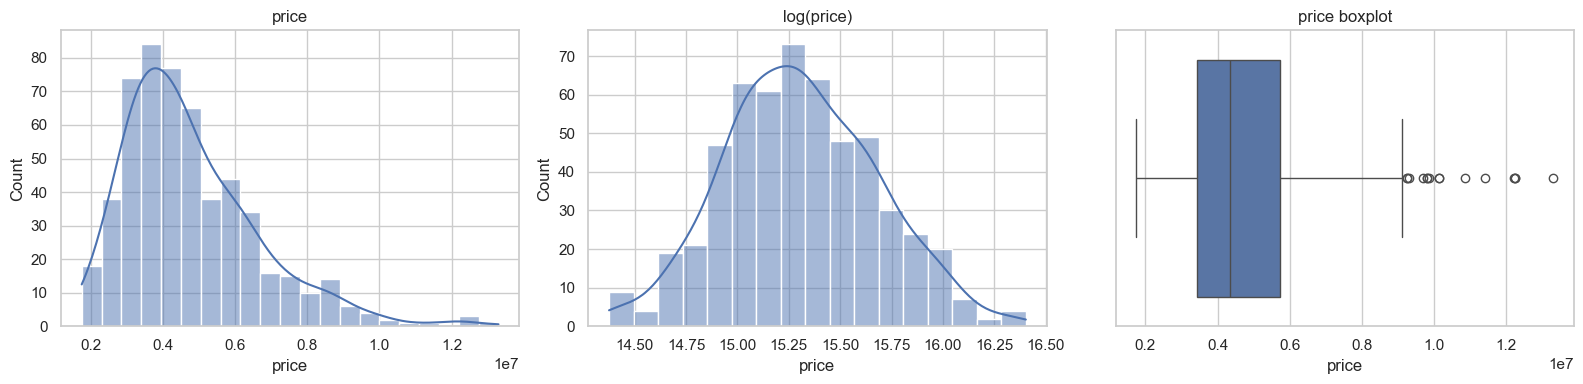

Skew price:      1.21
Skew log(price): 0.14


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["price"], kde=True, ax=axes[0]).set_title("price")
sns.histplot(np.log(df["price"]), kde=True, ax=axes[1]).set_title("log(price)")
sns.boxplot(x=df["price"], ax=axes[2]).set_title("price boxplot")
plt.tight_layout(); plt.show()

print("Skew price:     ", round(df["price"].skew(), 2))
print("Skew log(price):", round(np.log(df["price"]).skew(), 2))

## 3. Numeric features

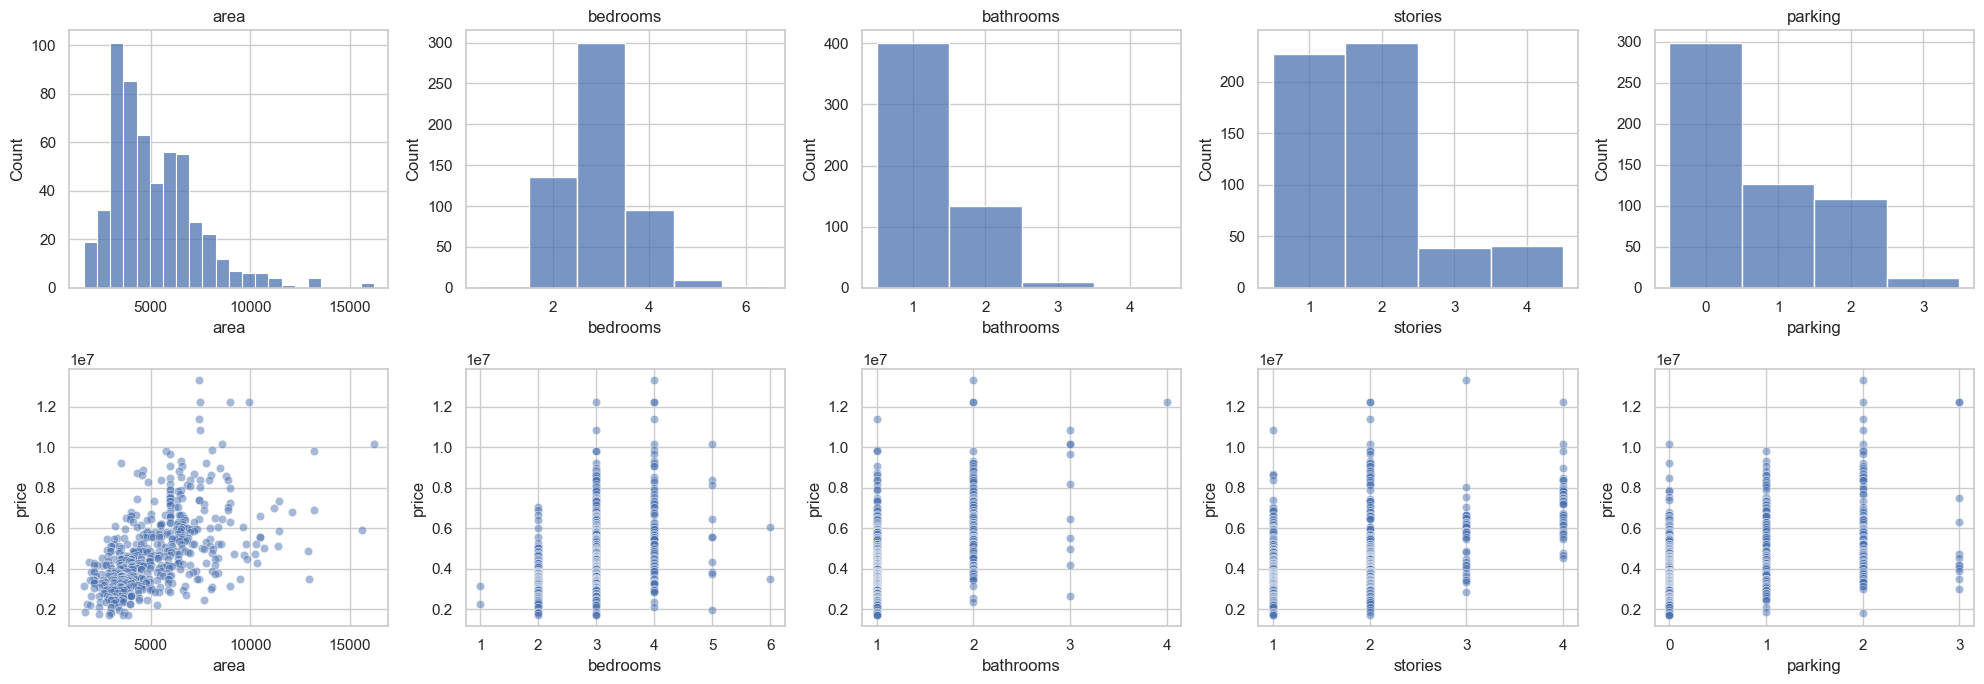

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(df[col], ax=axes[0, i], discrete=(col != "area")).set_title(col)
    sns.scatterplot(data=df, x=col, y="price", alpha=0.5, ax=axes[1, i])
plt.tight_layout(); plt.show()

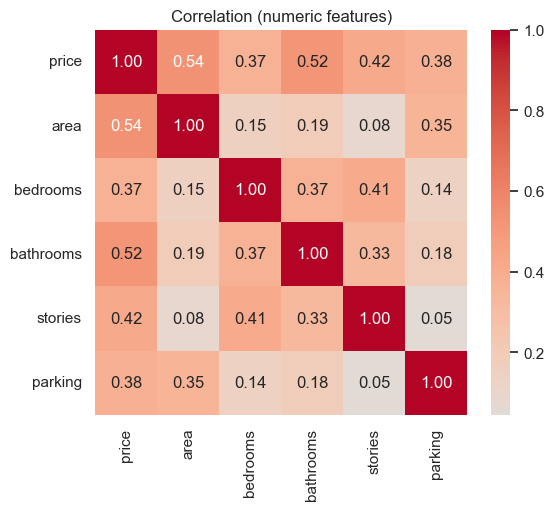

area        0.54
bathrooms   0.52
stories     0.42
parking     0.38
bedrooms    0.37
Name: price, dtype: float64

In [6]:
corr = df[["price"] + NUMERIC_FEATURES].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (numeric features)"); plt.show()

corr["price"].drop("price").sort_values(ascending=False)

`area` (0.54) та `bathrooms` (0.52) мають найсильніший лінійний зв’язок із ціною; зв’язок зі `stories`, `parking` і `bedrooms` слабший (0.37–0.42).

## 4. Categorical / yes-no features

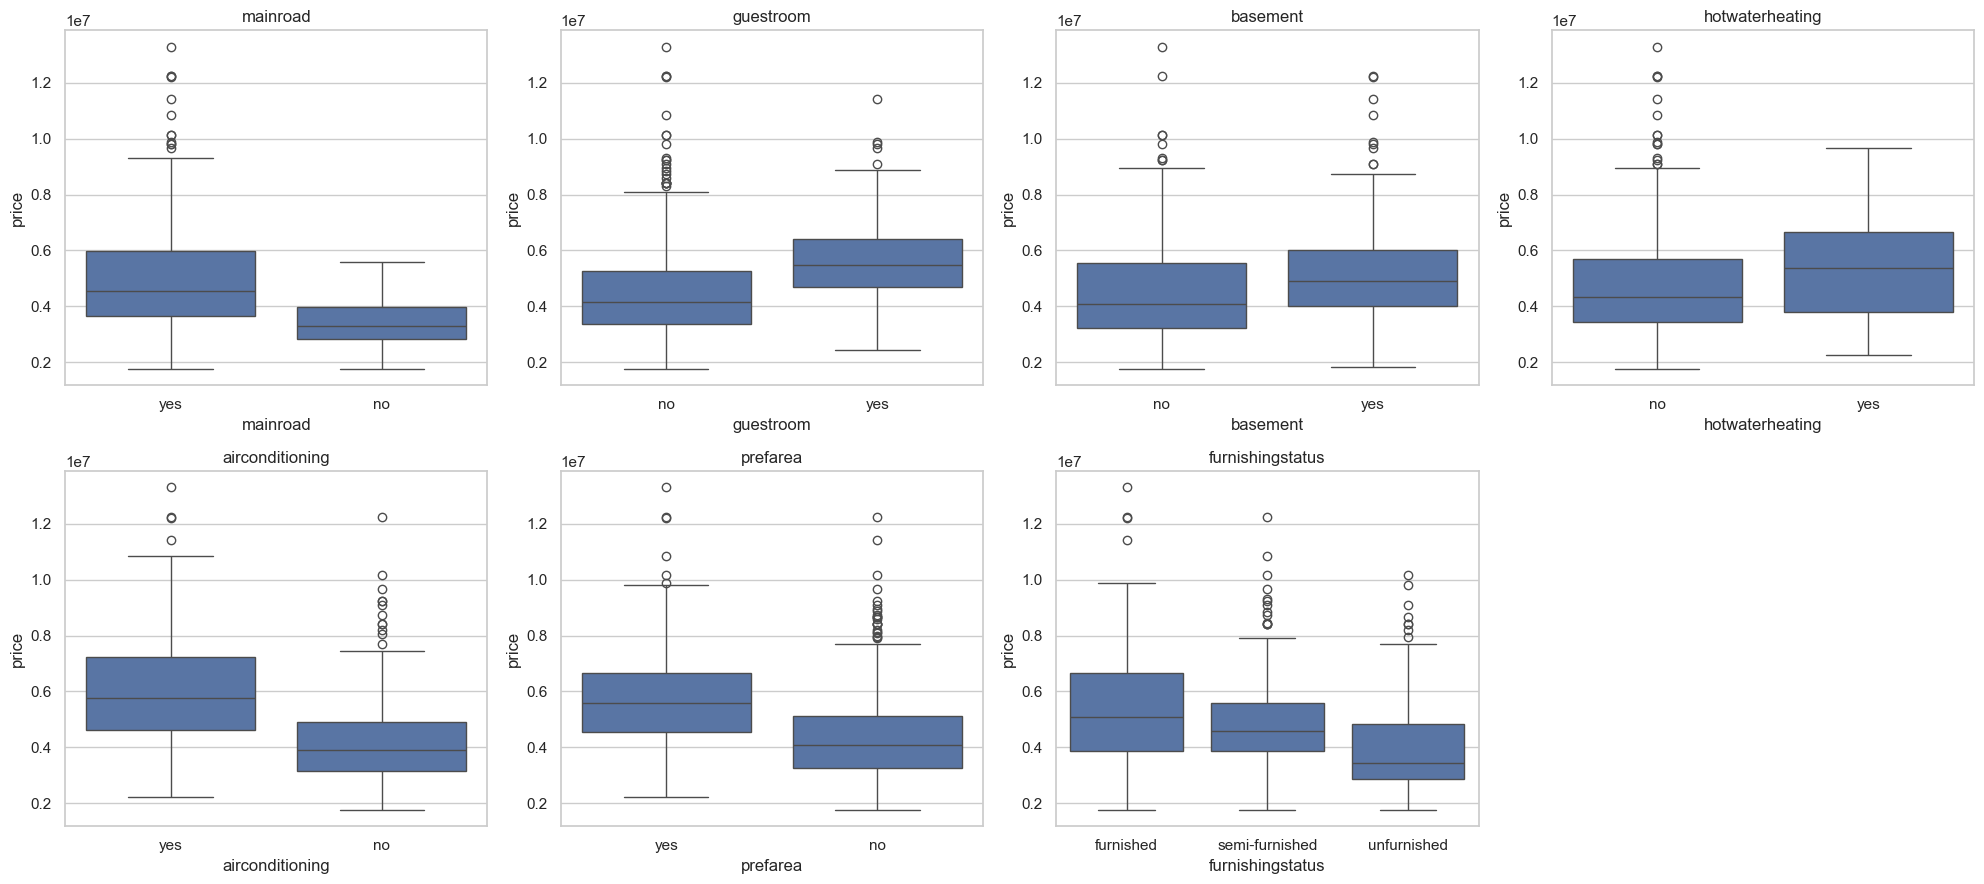

In [7]:
cat_cols = BINARY_FEATURES + CATEGORICAL_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=df, x=col, y="price", ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [8]:
summary = {c: df.groupby(c)["price"].agg(["count", "median"]) for c in cat_cols}
for c, t in summary.items():
    print(f"--- {c}"); print(t, "\n")

--- mainroad
          count       median
mainroad                    
no           77 3,290,000.00
yes         468 4,550,000.00 

--- guestroom
           count       median
guestroom                    
no           448 4,165,000.00
yes           97 5,495,000.00 

--- basement
          count       median
basement                    
no          354 4,077,500.00
yes         191 4,900,000.00 

--- hotwaterheating
                 count       median
hotwaterheating                    
no                 520 4,329,500.00
yes                 25 5,383,000.00 

--- airconditioning
                 count       median
airconditioning                    
no                 373 3,885,000.00
yes                172 5,757,500.00 

--- prefarea
          count       median
prefarea                    
no          417 4,095,000.00
yes         128 5,582,500.00 

--- furnishingstatus
                  count       median
furnishingstatus                    
furnished           140 5,075,000.00
semi-fu

Медіанні ціни вищі для значення «так» у кожній бінарній ознаці. Найбільша різниця спостерігається для `airconditioning` і `prefarea`; для `furnishingstatus` ціни впорядковані так: мебльовані > частково мебльовані > немебльовані. Зверніть увагу на дисбаланс класів: значення «так» для `hotwaterheating` мають лише 25 будинків, а значення «ні» для `mainroad` — лише 77.

## 5. Outliers

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()

pd.Series({c: iqr_outliers(df[c]) for c in ["price", "area"]}, name="IQR outliers")

price    15
area     12
Name: IQR outliers, dtype: int64

Є 15 викидів за ціною та 12 за площею (з 545 рядків). Вони виглядають як справжні великі/дорогі будинки, а не як помилки, а моделі на основі дерев до них стійкі, тому ми їх **залишаємо** (рядки не видаляємо).

## 6. Quick feature-engineering ideas

In [10]:
tmp = df.copy()
tmp["price_per_sqft"] = tmp["price"] / tmp["area"]       # for exploration only - uses the target!
tmp["total_rooms"] = tmp["bedrooms"] + tmp["bathrooms"]
tmp["area_per_room"] = tmp["area"] / tmp["bedrooms"]

tmp[["price", "total_rooms", "area_per_room"]].corr()["price"]

price           1.00
total_rooms     0.51
area_per_room   0.24
Name: price, dtype: float64

`price_per_sqft` використовує цільову змінну, тому його **не можна** використовувати як ознаку моделі (це призведе до витоку даних) — цей показник призначений лише для дослідницького аналізу. `total_rooms` і `area_per_room` — потенційні ознаки, які можна перевірити в `src/features.py`.

## Summary & decisions for modelling

- Відсутні пропуски та дублікати -> видалення не потрібне.
- `price` має правосторонню асиметрію -> спробувати навчання на `log(price)` і порівняти метрики (перетворити прогнози назад за допомогою `exp`).
- Кодувати так/ні як 0/1, one-hot кодувати `furnishingstatus`; для деревних моделей масштабування не потрібне.
- Зберігати викиди.
- Невеликий набір даних (545 рядків) -> використовувати крос-валідацію та бути обережним щодо перенавчання.
- Кандидатські ознаки, створені вручну: `total_rooms`, `area_per_room`.